# 1. Introduction

`PyRegTools` focuses on formulating and solving inverse problems sensibly. To demonstrate its features, the notebooks of the repository will introduce a few **toy problems** that model or solve somewhat realistic problems in science and engineering, aiming to provide a general starting point that we can use to consider more complex applications. The notebooks will focus on practical details and some important theoretical aspects, without aiming to cover them fully.

A basic form of an inverse problem is described by Eq. (1).

\begin{equation}
d(\mathbf{r},t)= f(\mathbf{\Theta}, \mathbf{r},t) + n(\mathbf{r},t),
\tag{1}
\end{equation}
where

* $d(\mathbf{r},t)$ represents the measured data as a function of the independent variables $\mathbf{r}$ (spatial) and $t$ (temporal);

Note: The measured data can be of any nature or scale. For example: Temperature [°C] or [K], electric voltage [V], electric current [A], electric field [V/m], magnetic field [Vs/m$^2$], velocity [m/s], acceleration [m/s$^2$], force [N], pressure [N/m$^2$], etc.

* $f(\mathbf{\Theta}, \mathbf{r}, t)$ represents the mathematical model, which, in addition to being a function of $\mathbf{r}$ and $t$, is also a function of a set of parameters $\mathbf{\Theta}$ (which is what we want to estimate);
  
* $n(\mathbf{r},t)$ represents the noise in every measurement (or even model discrepancies), causing our observation $d$ to differ from what the mathematical model $f$ would perfectly predict.

At this point, the nature of the function $f$ is still a mystery, as is that of the measured data, $d$. Most everyday phenomena are described using partial differential equations ($\textit{e.g.}$, the propagation of sound, electromagnetic waves, heat, and universal gravitation). Often, their solution can be expressed by the Fredholm integral of the first kind (and its variations). Such an integral equation is given by

\begin{equation}
d(s) = \int_{0}^{1}K(s,t) u(t) \text{d}t.
\tag{2}
\end{equation}

In this formulation:

* $d(s)$ represents the measured data as a function of a generic variable $s$. You can think of $s$ as the independent variable along which the data is measured ($\textit{e.g.}$, space, time);
* $K(s,t)$ is known as the kernel, a function of $s$ and the integration variable $t$. We will see how the nature of the kernel changes depending on the physics of the problem, but you can think of $t$ as an independent variable along which the desired solution is computed;
* $u(t)$ is the source term (or the cause behind the measured data). It is precisely $u(t)$ that we want to determine, and it may even have units different from those of $d(s)$ ($\textit{e.g.}$, suppose you measure sound pressure [N/m$^2$] in front of a sound source and want to determine its vibration velocity in [m/s]).

# 2. Gravity survey problem

One of the problems we will investigate in detail is estimating the density, $\rho(x)$, through the 1D space, which gives rise to a measured gravitational field $g(x')$ at a certain distance from the source. A schematic of the problem is shown in Fig. 1. Such problems arise in geophysics. We have the means to measure the acceleration due to gravity ([m/s$^2$]) at the surface, but we want to determine the density of the material ([kg/m$^3$]) at a depth below it. The goal might be, for example, to determine the density of rocks, whether there are volumes of water or gas below the surface, etc.

<figure style="text-align: center;">
    <img src="figures\gravity.svg" width="700" alt="gravity survey conceptual image.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figure 1: Schematics of the gravity survey problem.
    </figcaption>
</figure>

Let’s rewrite Eq. (2) to align it with the notation of the problem at hand.

\begin{equation}
g(x') = \int_{0}^{1}K(x',x) \rho(x) \text{d}x
\end{equation}

The gravitational field of an infinitesimally small region with density $\rho(x)$ and length $\text{d}x$ is

\begin {equation}
\rho(x) \text{d} x / r^2,
\end{equation}

where $r = \sqrt{d^2 + (x' - x)^2}$ is the distance between the “**source point**” at $x$ and the “**measured point in the field**” at $x'$. The direction of the gravitational field is from the “**field measurement point**” toward the “**source point**”; therefore, the measured value of $\text{d}g(x')$ (caused by the infinitesimal source point) is

\begin{equation}
\text{d}g(x') = \text{sin}(\theta)\frac{\rho(x) \text{d}x}{r^2}
\end{equation}
where $\text{sin}(\theta) = d/r$. Thus, the total value of the acceleration due to gravity, $g(x')$, is the integral of all the infinitesimal terms given in the previous equation, namely

\begin{equation}
g(x') = \int_{0}^{1}\frac{d}{[d^2+(x' - x)^2]^{3/2}} \rho(x) \text{d}x,
\tag{3}
\end{equation}
which is the Fredholm integral for the **gravity survey** problem, with the kernel given by

\begin{equation}
K(x',x) = \frac{d}{[d^2+(x' - x)^2]^{3/2}}.
\end{equation}

The physical dimension of the density, in this 1D case, is $\rho(x)$ [kg/m]. The universal gravitational constant, $G$ [Nm$^2$/kg$^2$], is missing, but it will not be much of an issue for our purposes, since it will only scale the problem’s sensing matrix.

## 2.1. Discretization

We can now begin interacting with the Gravity survey problem of `PyRegTools`. The first step is to recognize that the integral equation in Eq. (3) needs to be discretized. A good starting point is to use some quadrature rule. When we do this, Eq. (3) becomes

\begin{equation}
d(s) = \int_{0}^{1}K(s,t) u(t) \text{d}t \approx \sum\limits_{j = 1}^{L}w_jK(s, \xi_j)u(\xi_j),
\tag {4}
\end{equation}
where $w_j$ are the weights of the quadrature rule and $\xi_j$ are the points sampled along the integration domain. Furthermore, we want to estimate the variable $s$ at some discrete points, such that $\mathbf{s} = [s_1, s_2, \cdots, s_M]^T$ and

\begin{equation}
d(s_i) \approx \sum\limits_{j = 1}^{L}w_jK(s_i, \xi_j)u(\xi_j).
\tag{5}
\end{equation}

Clearly, Eq. (5) is an inner product between the vectors $[w_1 K(s_i,\xi_1), w_2 K(s_i,\xi_2), \cdots, w_L K(s_i,\xi_L)]^T$ (**kernel**) and $[u(\xi_1), u(\xi_2), \cdots, u (\xi_L)]^T$ (**source term**). When we take all measurements into account, we have the following linear system of equations:

\begin{equation}
\underbrace{\begin{bmatrix}
d(s_1) \\ d(s_2) \\ \vdots \\ d(s_M)
\end{bmatrix}}_{\text{measurement}}
=
\underbrace{\begin{bmatrix}
w_1 K(s_1, \xi_1) & w_2 K(s_1, \xi_2) & \cdots & w_L K(s_1, \xi_L)\\
w_1 K(s_2, \xi_1) & w_2 K(s_2, \xi_2) & \cdots & w_L K(s_2, \xi_L)\\
\vdots & w_2 \vdots & \ddots & \vdots\\
w_1 K(s_M, \xi_1) & w_2 K(s_M, \xi_2) & \cdots & w_L K(s_M, \xi_L)\\
\end{bmatrix}}_{\text{sensing matrix}}
\underbrace{\begin{bmatrix}
u(\xi_1) \\ u(\xi_2) \\ \vdots \\ u(\xi_L)
\end{bmatrix}}_{\text{unknowns}}
\tag{6}
\end{equation}

`PyRegTools` embeds some discretization rules in the `toyproblems` module. In `Gravity1D`, for instance, the source term can be discretized using the Mid-Point rule or the Gauss-Legendre quadrature. Let's see what that looks like (note how the geometry of the source term changes).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyregtools
from pyregtools.toyproblems.gravity import Gravity1D
from pyregtools import regsolvers
from pyregtools import regchoice

In [2]:
def plot_measurement(problem, x_sol = None, source_lim = (0, 2.5), b_lim = (0, 5)):
    """ Helping function to do specific plots of source terms and measured signals.
    """
    fig, axs = plt.subplots(1, 2, figsize = (9,3))
    axs[0].plot(problem.x, problem.x_true, '--k')
    if x_sol is not None:
        axs[0].plot(problem.x, x_sol, 'royalblue', alpha = 0.8)
    axs[0].grid(linestyle = '--')
    axs[0].set_xlim((problem.lb, problem.ub))
    axs[0].set_ylim((source_lim[0],source_lim[1]))
    axs[0].set_xlabel(r'$x$')
    axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
    axs[0].set_title(r'Source term')
    axs[1].plot(problem.coord, problem.b_true, color = 'k', label = r'Noiseless measurement')
    if hasattr(problem, "b_noisy"):
        axs[1].plot(problem.coord, problem.b_noisy, color = 'royalblue', label = r'Noisy measurement', alpha = 0.8)
    axs[1].grid(linestyle = '--')
    axs[1].set_xlim((problem.lb, problem.ub))
    axs[1].set_ylim((b_lim[0], b_lim[1]))
    axs[1].legend()
    axs[1].set_xlabel(r'$x´$')
    axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
    axs[1].set_title(r'Measured accleration ($d = {}$ m)'.format(problem.d))
    plt.tight_layout()

#### Mid-Point rule

Note how the samples (in blue) along the density source are uniformily spaced.

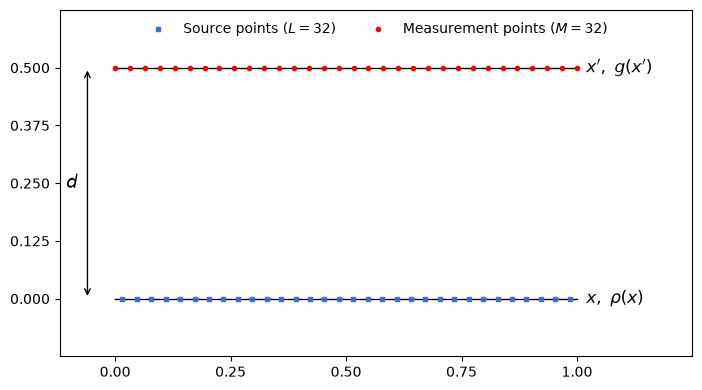

In [3]:
problem = Gravity1D(lb = 0, ub = 1, d = 0.5) # instantiate Gravity 1D
problem.sample_g(M = 32) # sample the measurement space uniformily
problem.sample_rho_mp(L = 32) # sample source term with mid-pt rule
problem.plot_problem(); # plot the resulting problem

#### Gauss-Legendre quadrature

Note how the samples (in blue) along the density source are not uniformily spaced.

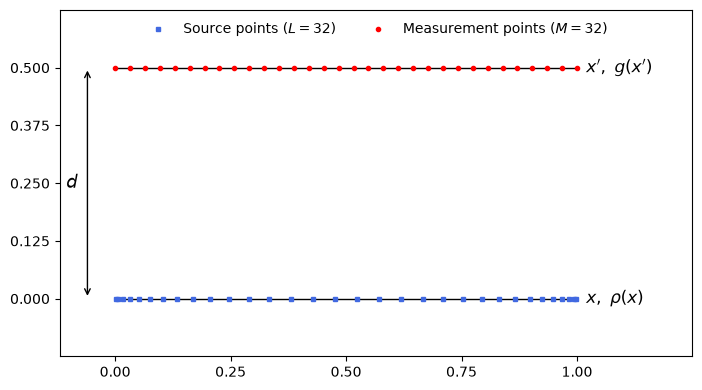

In [4]:
problem.sample_rho_gauss_legendre(L = 32) # sample source term with Gauss-Legendre rule
problem.plot_problem(); # plot the resulting problem

## 2.2. Forward problem

Following the convention in Eq. (6), a discrete forward problem is given by

\begin{equation}
\mathbf{b} = \mathbf{Ax},
\tag{7}
\end{equation}
where $\mathbf{b} \in \mathbb{C}^{M \times 1}$ is the measurement vector, $\mathbf{A} \in \mathbb{C}^{M \times L}$ contains the convolution kernels associated with the forward model, and  $\mathbf{x} \in \mathbb{C}^{L \times 1}$ is the desired solution vector.

`PyRegTools` can be used to compute the **sensing matrix**, $\mathbf{A}$, and **true source terms** expressed as a vector $\textbf{x}_{\text{true}}$. Thus, one can compute a **noiseless measurement** vector expressed as $\textbf{b}_{\text{true}}$. To simulate realistic measurements, `PyRegTools` allows us to add noise to noiseless measurements (stored in $\textbf{b}_{\text{noisy}}$). In ``Gravity1d``, the available source terms are 1D density distributions, and the measurement vectors are gravity acceleration.

Let us further study ``Gravity1d`` to understand the structure of the toy problems. 

Shape of the sensing matrix: (64, 51)
Shape of the noiseless measurement vector: (64,)
Shape of the noisy measurement vector: (64,)
Shape of the source term vector: (51,)


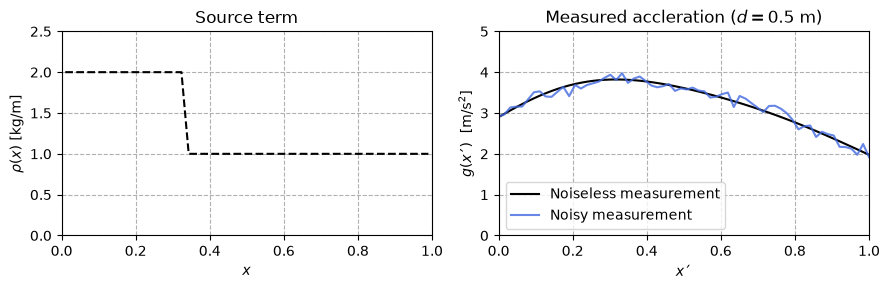

In [5]:
problem = Gravity1D(lb = 0, ub = 1, d = 0.5) # Instantiate
problem.sample_g(M = 64) # sample the gravity acceleration
problem.sample_rho_mp(L = 51) # sample the source term
problem.sens_mtx() # build the sensing matrix
problem.density_piecewise() # create a source term
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = 30) # add some noise

print("Shape of the sensing matrix: {}".format(problem.A.shape))
print("Shape of the noiseless measurement vector: {}".format(problem.b_true.shape))
print("Shape of the noisy measurement vector: {}".format(problem.b_noisy.shape))
print("Shape of the source term vector: {}".format(problem.x_true.shape))

plot_measurement(problem) # use helper function to plot source terms and measurements.

## 2.3. Distance and spectrum

We can study how the measured quantity varies as the measurement distance and the source-term spectrum change. 

What you will notice as the distance increases is:

- the farther we measure from the source (the origin of the phenomenon), the smaller the amplitude of the measured quantity (the consequence);
- apparently, the measured quantity also becomes smoother or exhibits less variation across space.

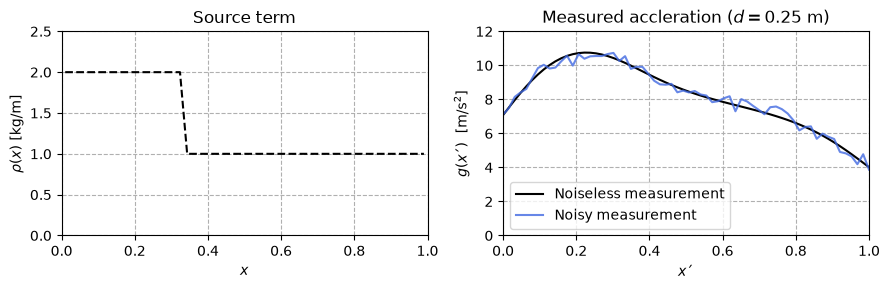

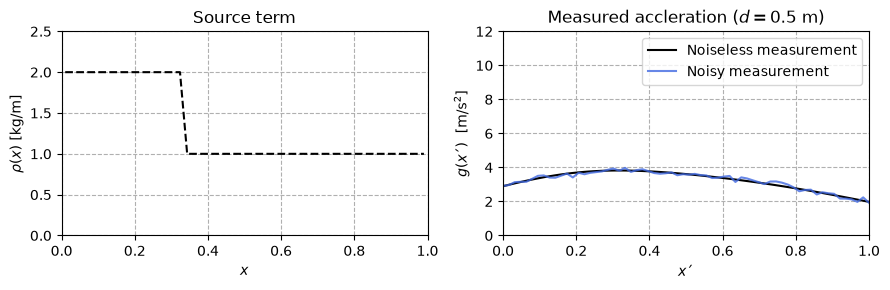

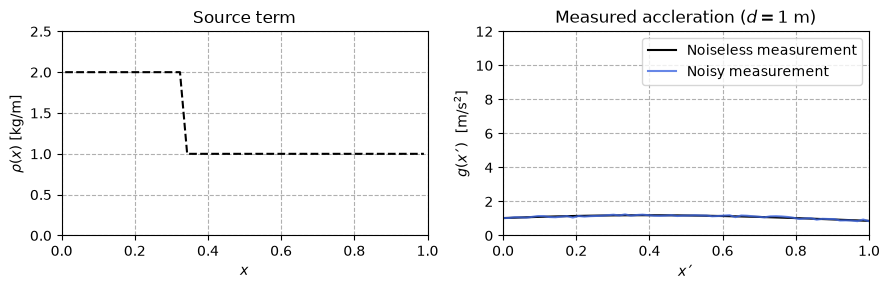

In [6]:
# measured distances
distances = [0.25, 0.5, 1]
for d in distances:
    problem = Gravity1D(lb = 0, ub = 1, d = d) # Instantiate
    problem.sample_g(M = 64) # sample the gravity acceleration
    problem.sample_rho_mp(L = 51) # sample the source term
    problem.sens_mtx() # build the sensing matrix
    problem.density_piecewise() # create a source term
    problem.noiseless_meas() # compute true measurement
    problem.add_noise(snr = 30) # add some noise
    plot_measurement(problem,  b_lim = (0,12))

Now, we can create a source term with a single and varying frequency and see what happens. What you will notice is

- Smaller amplitudes are caused by: **greater measurement distances** and **higher spatial frequencies** in the underlying phenomenon.
- The smaller amplitudes in $g(x^{'})$ (associated with the higher frequencies) tend to be **more corrupted by noise**;
- When attempting to infer high-spatial-frequency components in $\rho(x)$ from noisy data in $g(x^{'})$, noise **amplification** will occur.
- If we are not careful, we will end up compromising our solution.

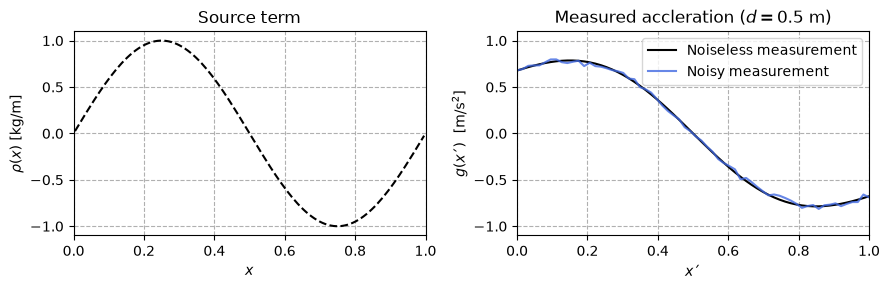

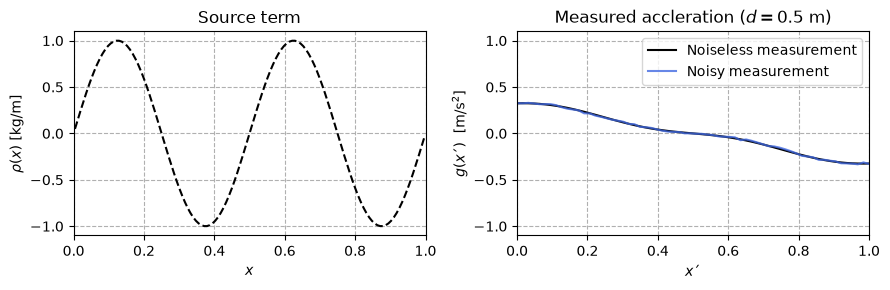

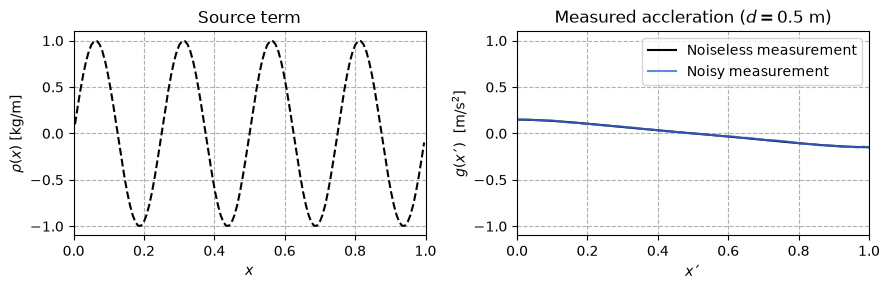

In [7]:
fp = [1, 2, 4]
for f in fp:
    problem = Gravity1D(lb = 0, ub = 1, d = 0.5) # Instantiate
    problem.sample_g(M = 64) # sample the gravity acceleration
    problem.sample_rho_mp(L = 128) # sample the source term
    problem.sens_mtx() # build the sensing matrix
    problem.density_sin(amplitude = 1.0, kx = 2*np.pi*f) # create a source term
    problem.noiseless_meas() # compute true measurement
    problem.add_noise(snr = 30) # add some noise
    plot_measurement(problem, source_lim = (-1.1,1.1), b_lim = (-1.1,1.1))

## 2.4. Inverse problem via the naive solution

Before we dive into the theory of inverse problems, let’s see what happens with the **naive** solution given by in a medium-scale problem, even when $\mathbf{b}$ is perfectly measured.

\begin{equation}
\mathbf{x} = \mathbf{A}^{-1}\mathbf{b}_{\text{true}},
\tag{8}
\end{equation}
where now $\mathbf{A}$ must be a square and invertible matrix.

You’ll see that the naive solution is often useless, especially as the number of measurements and unknowns increases. This occurs because as the order of the problem increases, the condition number of $\mathbf{A}$ becomes excessively large, potentially reaching $\text{cond}(\mathbf{A})\approx 10^{17}$ for $n=32$. Thus, even numerical rounding errors cause the naive solution to blow up.

**NOTE:** There is no noise here, but imagine how much worse the effect of the condition number will be in a real-world situation with noise. 

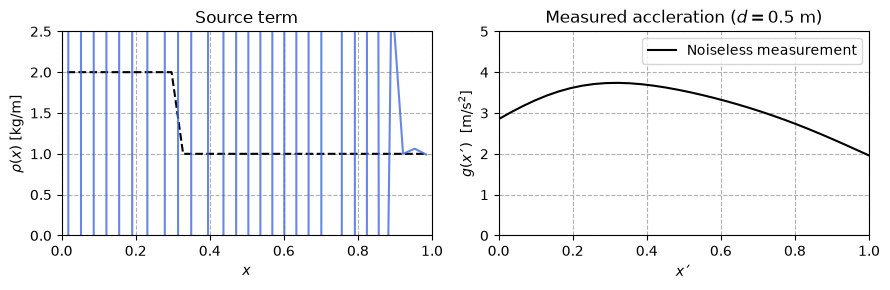

In [8]:
problem = Gravity1D(lb = 0, ub = 1, d = 0.5) 
problem.sample_g(M = 32) 
problem.sample_rho_mp(L = 32)
problem.sens_mtx()
problem.density_piecewise()
problem.noiseless_meas() 

x_naive = np.linalg.inv(problem.A) @ problem.b_true
plot_measurement(problem,x_naive)

# 3. Singular Value Decomposition

One of the core components in the theory of inverse problems is the Singular Value Decomposition (SVD). Instead of diving deep into the theory, we can focus on the important aspects.

The SVD is a fundamental technique in linear algebra that decomposes (or factors) a **rectangular** matrix $\mathbf{A} \in \mathbb{C}^{M \times L}$ into a product of three simpler matrices (**two orthogonal matrices and one diagonal matrix**)

\begin{equation}
\textbf{A} = \textbf{U} \Sigma \textbf{V}^H=\sum\limits_{i=1}^{L}\textbf{u}_i \sigma_i \textbf{v}_{i}^{H}.
\tag{9}
\end{equation}

The SVD has a very concrete connection to the analysis of discrete inverse problems and to the **regularization** techniques used to stabilize the process of finding or approximating a solution. This is not the only way to decompose a matrix, but it will certainly teach us a great deal about how to find a **reasonable** solution to a complex inverse problem.

An important note is that the SVD decomposition is not **unique**. When using different packages (such as NumPy or SciPy), you will obtain different results (or even when using different programming languages). However, this fact generally does not have a major impact on the regularization algorithms we will study with `PyRegTools`.

You can use `PyRegTools` with real or imaginary data and models. Furthermore, the module `regsolvers` exposes the function `csvd` (compact SVD), which can handle underdetermined or overdetermined systems of equations. The way it is implemented makes it useful for the functionalities in `PyRegTools`.

It is also worth noting that for inverse problems of very large dimensions (when $M$ or $L$ exceed the thousands), the SVD decomposition can become computationally very expensive. In these cases, we will try to obtain **reasonable** solutions using iterative methods, which rely solely on the inner product operation on the rows and columns of $\mathbf{A}$. `PyRegTools` has mechanisms for such approaches implemented in the `iterativesolvers` module.

## 3.1. Properties of the SVD

Matrices $\textbf{U} \in \mathbb{C}^{M \times L}$ and $\textbf{V} \in \mathbb{C}^{L \times L}$ (for $M\geq L$) are composed of column vectors called:

- left singular vectors: $\textbf{U} = [\textbf{u}_1, \textbf{u}_2, \cdots, \textbf{u}_M]$
- right singular vectors: $\textbf{V} = [\textbf{v}_1, \textbf{v}_2, \cdots, \textbf{v}_L]$

and both matrices have orthonormal columns:

- $\textbf{u}_{i}^{H}\textbf{u}_{j} = \textbf{v}_{i}^{H}\textbf{v}_{j} = \delta_{ij}$, or
- $\textbf{U}^{H}\textbf{U} = \textbf{V}^{H}\textbf{V} = \textbf{I}$.

The matrix $\Sigma \in \mathbb{R}^{L \times L}$ is the singular values matrix. This matrix is diagonal, and the singular values are arranged in **decreasing** order, namely:

\begin{equation}
\Sigma = \text{diag}(\sigma_1, \sigma_2, ..., \sigma_L), \ \ \ \ \ \ \ \sigma_1 \geq \sigma_2 \geq \cdots \sigma_L.
\tag{10}
\end{equation}

The condition number of a matrix $\textbf{A}$ is

\begin{equation}
\text{cond}(\mathbf{A}) = \sigma_1 / \sigma_L,
\tag{11}
\end{equation}
which means it tends to grow as the matrix size increases because $\sigma_L$ will decrease. That, in turn, renders the naive solution of Eq. (8) useless.

## 3.2. Pseudoinverse

The SVD can be used to compute the **pseudoinverse** (associated with the least-squares solution) as follows:

\begin{equation}
\textbf{A}^{\dagger} = \textbf{V} \Sigma^{-1} \textbf{U}^H.
\tag{12}
\end{equation}

**Note:**
- You do not need to invert the matrices $\textbf{U}$ and $\textbf{V}$ (since they are orthogonal), and calculating their Hermitian is trivial.
- The matrix $\Sigma^{-1}$ is also trivial to compute. Its components are:

\begin{equation}
\sigma_{\text{inv}} =
\begin{cases}
1/\sigma_i, \ \ \text{if} \ \ \sigma_i \neq 0 \\ \\
0, \ \ \ \ \ \ \ \ \text{if} \ \ \sigma_i = 0 \\
\end{cases}.
\end{equation}

Therefore, for a matrix $\Sigma$ with nonzero components, the structure of $\Sigma^{-1}$ is

\begin{equation}
\Sigma^{-1} = 
\begin{bmatrix}
\sigma_{1}^{-1} & 0 & \cdots & 0 \\
0 & \sigma_{2}^{-1} & \cdots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \cdots & \sigma_{L}^{-1} \\
\end{bmatrix}.
\tag{13}
\end{equation}

or 

\begin{equation}
\Sigma^{-1} = \text{diag}(\sigma_{1}^{-1}, \sigma_{2}^{-1}, \cdots, \sigma_{L}^{-1}).
\tag{14}
\end{equation}

The associated least-squares solution is

\begin{equation}
\textbf{x} = \textbf{A}^{\dagger}\textbf{b} = (\textbf{V} \Sigma^{-1} \textbf{U}^H) \textbf{b} =  \sum\limits_{i=1}^{L}\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i},
\tag{15}
\end{equation}

We can remark a few important terms in Eq. (15)

- Since $\sigma_i$ appears in the denominator and decreases as $i$ increases, each term in the sum tends to be larger than the previous one (amplification of the solution). This is what causes the solution to tend toward instability.
- $\boldsymbol{\beta} = \textbf{u}_{i}^{H}\textbf{b}$ represents the projection of the measured data into the columns of the left singular vectors matrix.

Thus, we can already establish an interesting connection between the sensing matrix of the problem and the frequency components of the measurement vector. 

Let's set up the problem again and use `PyRegTools` to compute the SVD and to plot the column vectors of the matrix $\mathbf{U}$. You will notice that as the index increases, the corresponding column vector oscillates more and more rapidly. This means that the smaller singular values, $\sigma$, correspond to higher frequencies in the measured signal (including the noise projection of $\mathbf{b}$ onto $\mathbf{U}$). 

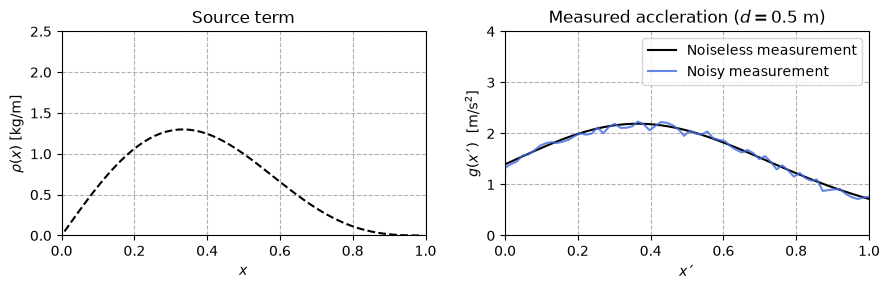

In [9]:
problem = Gravity1D(lb = 0, ub = 1, d = 0.5) 
problem.sample_g(M = 64) 
problem.sample_rho_mp(L = 64)
problem.sens_mtx()
problem.multi_density_sin(amplitude = [1.0, 0.5], kx = [np.pi, 2*np.pi]) 
problem.noiseless_meas()
snr = 30
problem.add_noise(snr = snr, seed = 10)
plot_measurement(problem, b_lim = (0,4))

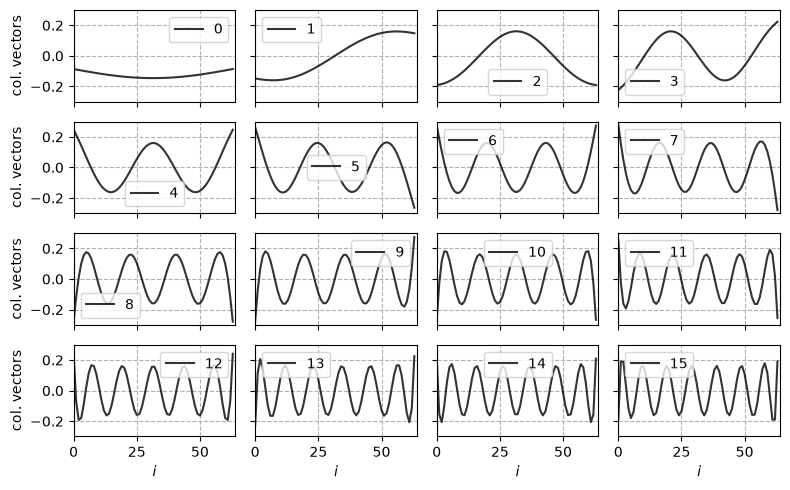

In [10]:
u,s,v = regsolvers.csvd(problem.A)
pyregtools.utils.plot_colvecs(u, rows = 4, cols = 4, figsize = (8,5), ylim = (-0.3,0.3))

## 3.3. Picard plot

Let’s analyze the components of the sum in Eq.(15) to assess the inverse problem. In particular, we are interested in plotting the following quantities:

- the singular values: $\sigma_i$
- the values: $|\textbf{u}_{i}^{H}\textbf{b}|$
- the values: $|\textbf{u}_{i}^{H}\textbf{b}| / \sigma_i$

This corresponds to the Picard plot, a helpful tool for analyzing the inverse problem (readily accessible in the module `utils` of `PyRegTools`). Let's inspect what happens with the **noiseless** measurement.

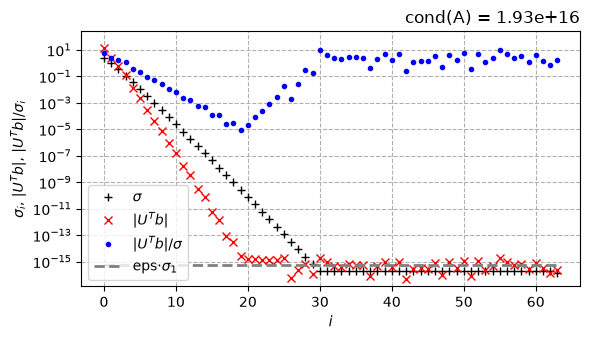

In [11]:
pyregtools.utils.plot_picard(u,s, problem.b_true, noise_norm = None, figsize = (6,3.5))

**Notice a few things**

-  The **singular values** decay rapidly;
-  For $i \geq 30$, they tend to stabilize near the machine’s *eps*. This is due to the influence of **finite-precision** arithmetic;
-  These small singular values are, in fact, smaller than the machine’s precision $\text{eps} \times \sigma_1$, and **are not reliable** for matrix inversion;
-  $\text{cond}(\textbf{A}) > 10^{16}$, which, for all practical purposes, is infinite

Also

-  The coefficients <span style="color:red"> *$|\textbf{u}_{i}^{H}b|$*</span>  decay more rapidly than the singular values, until they stabilize for $i \approx 20$ at a level determined by the machine's precision;
-  The coefficients of the solution <span style="color:blue"> *$|\textbf{u}_{i}^{T}b|/\sigma_i$*</span> also decay (for $i < 20$);
-  For $i > 20$, the coefficients <span style="color:blue"> *$|\textbf{u}_{i}^{T}b|/\sigma_i$*</span> begin to increase again due to the imprecise values of <span style="color:red"> *$|\textbf{u}_{i}^{T}b|$*</span>
-  And once again, it is these coefficients ($i > 20$) that will cause the naive solution to become unstable.

Now, look at how much worse it gets when the noisy measurement is taken into account.

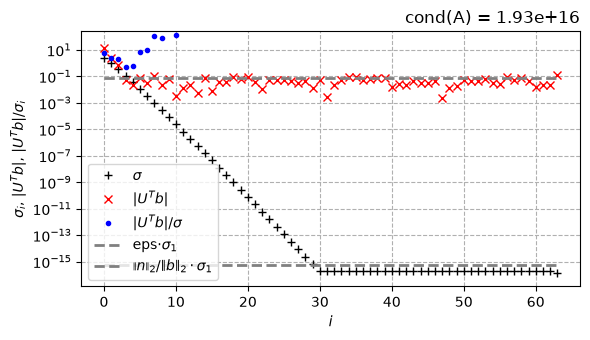

In [12]:
noise_norm = 10**(-snr / 20) * np.linalg.norm(problem.b_true)
pyregtools.utils.plot_picard(u,s, problem.b_noisy, noise_norm = noise_norm, figsize = (6,3.5))

## 3.4. The discrete Picard Condition

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
Let $\tau$ be the $\textbf{level}$ at which the computed singular values,  $\sigma_i$, become constant due to rounding errors. The discrete Picard condition is satisfied if, for all singular values greater than $\tau$, the corresponding coefficients $|\textbf{u}_{i}^{T}b|$ decay, on average, faster than the $\sigma_i$.
</div>

<br>
Thus, for the problem at hand, the Picard conditions appeared to be satisfied only for the first 4 or 5 singular values.
<br>

<br>
<div style="background-color:  #f0f2f5; padding: 5px; border-radius: 20px; text-align: center;  margin: 0 auto; max-width: 300px">
  <h2 style="margin: 20;">The story so far</h2>
</div>

Even **without noise** in the data (which is never the case in real-world measurements), we cannot expect the **naive** solution to be a **reasonable** solution to the discrete inverse problem. The influence of finite-precision errors is sufficient to render the **naive** solution completely useless. We do not observe this in small-scale problems because the smallest singular value will not be that small. But for any problem of practical interest, with 2 or 3 dozen measurements and unknowns, the **naive** solution will fail even if there is no noise.

The large condition number of matrix $\mathbf{A}$ and the presence of noise mean that the naive solution is very sensitive to any perturbation on the right-hand side of $\mathbf{Ax} = \mathbf{b}$ (noise in the measured data). Specifically, suppose that the **exact** and **perturbed** solutions $\textbf{x}_{\text{exa}}$ and $\textbf{x}$ satisfy

\begin{equation}
\textbf{A} \textbf{x}_{\text{exa}} = \textbf{b}_{\text{exa}} \ \ \ \ \& \ \ \ \ \textbf{A} \textbf{x} = \textbf{b} = \textbf{b}_{\text{exa}} + \textbf{n}
\end{equation}

From perturbation theory, we have the following limits:

\begin{equation}
\frac{\left\|\textbf{x}_{\text{exa}}-\textbf{x}\right\|_{2}}{\left\|\textbf{x}_{\text{exa}}\right\|_{2}} \leq \text{cond}(\textbf{A})\frac{\left\|\textbf{n}\right\|_{2}}{\left\|\textbf{b}_{\text{exa}}\right\|_{2}}
\tag {16}
\end{equation}
and since $\text{cond}(\textbf{A})$ can be very large, the left-hand side of Eq. (16) can be arbitrarily large. This implies that the difference between $\textbf{x}_{\text{exa}}$ and $\textbf{x}$ can be **arbitrarily** large if nothing is done.

Now, we use the knowledge we have built up so far to devise different methods for calculating **reasonable solutions** (approximations) that are **less sensitive** to perturbations and noise than the naive solution. These methods are called **regularization methods** because they impose regularity on the computed solution—typically in the form of a requirement that the **solution be smooth**, in some sense. And by imposing this regularity, or smoothness, we suppress some unwanted noise components (i.e., high-frequency components associated with the smallest singular values), leading to more stable approximate solutions. Almost all of the regularization methods covered in this chapter produce solutions that can be expressed as an SVD expansion.

### Quantifying the quality of the solution

In our toy problems, we know the true solution, stored in ``x_true``. Let's try to quantify how far apart $\textbf{x}_{\text{true}}$ and $\textbf{x}$ are using the Normalized Mean Square Error, given by

\begin{equation}
\text{NMSE} = \frac{\left\|\textbf{x}_{\text{true}}-\textbf{x}\right\|_2^2}{\left\|\textbf{x}_{\text{true}}\right\|_2^2}
\tag{17}
\end{equation}

# 4. Regularization Methods

Let's try some regularization methods implemented in ``PyRegTools``. For now, we will use the module `regsolvers`.

## 4.1. Constrained optimization

One way to impose regularity is to create a constrained optimization problem. In ``PyRegTools`` you can use the solver ``regsolvers.cvx_constrained`` to solve the following problem

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|^{2}_{2}), \ \ \, \text{subject to} \ \ \ \left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq \nu \ \left\|\textbf{n}\right\|^{2}_{2}.
\tag{18}
\end{equation}

The idea here is to

- minimize the norm of the solution, $\mathbf{x}$;
- subject to the condition that the norm of the residual, $\textbf{Ax -  b}$, be less than or equal to the product of some factor $\nu$ and the norm of the noise, $\textbf{n}$. Let’s investigate how this works. To do so, we need to assume that we “know” $\textbf{n}$ with some degree of confidence. 
Let’s investigate how the gravity survey problem behaves under different choices of $\nu$.

In [13]:
nus = [40,10, 1.2, 1, 0.95, 0.90]
x_est = []
nmse = []
sol_norm = []
res_norm = []
for nu in nus:
    xh = regsolvers.cvx_constrained(problem.A, problem.b_noisy, nu*noise_norm )
    x_est.append(xh)
    nmse.append(pyregtools.utils.nmse_fun(xh, problem.x_true))
    sol_norm.append(np.linalg.norm(xh))
    res_norm.append(np.linalg.norm(problem.A @ xh - problem.b_noisy))

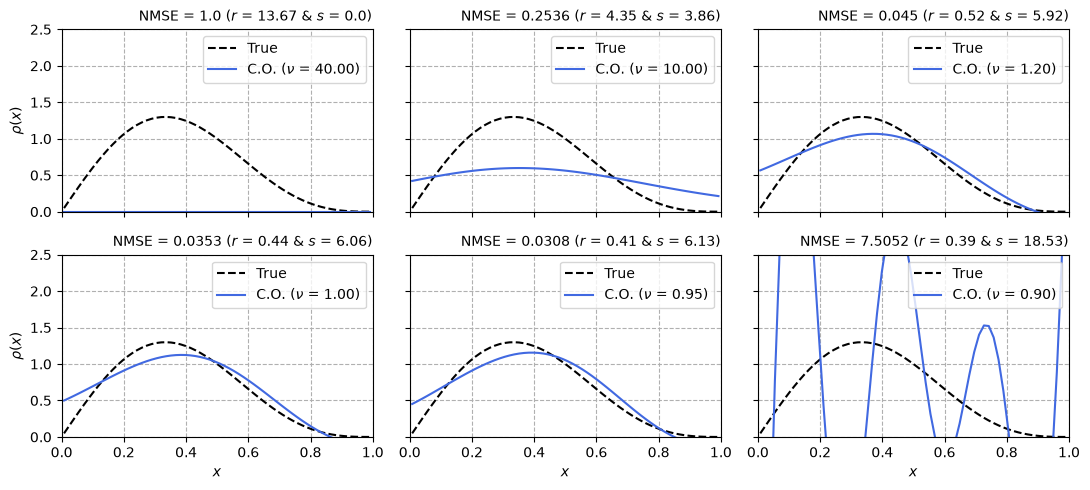

In [14]:
fig, axs = plt.subplots(2, 3, figsize = (11,5), sharex=True, sharey=True)
j = 0
for row in np.arange(2):
    for col in np.arange(3):
        axs[row,col].plot(problem.x, problem.x_true, '--k', label = 'True')
        axs[row,col].plot(problem.x, x_est[j], color = 'royalblue', label = r'C.O. ($\nu$ = {0:.2f})'.format(nus[j]))
        axs[row,col].set_title(r'NMSE = {} ($r$ = {} & $s$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[1,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

### What we notice is

- If $\nu$ is too high, it is like we estimated the noise norm to be too high (overestimated), which tends to invade the noiseless part of the data. In this case, the optimizer was instructed to stay so far away from the noise floor that it ends up suppressing useful components of the source term. The consequence is a solution that tends to be over-smoothed. Then, it is likely that our optimization problem will discard useful information contained in the measured data and generate solutions with high residuals (sometimes even close to zero). The problem is over-regularized, leading to **underfitting**.
- As $\nu$ decreases (our margin above the noise floor), the NMSE decreases in principle. The effect appears to stabilize as $\nu \rightarrow 1$; when $\nu$ falls below $1.0$, the NMSE begins to increase again, rising sharply. The reason is that we are forcing the optimizer to find the solution within the noise level. Numerically, the optimizer will raise an error if $\nu$ is reduced too much.
- As $\nu$ decreases, the norm of the residual ($r$) decreases. Surprisingly, this is true even for $\nu<1.0$. This is **overfitting** or an under-regularized solution;
- note that the norm of the solution, $s$, increases as $\nu$ decreases. When $\nu<1.0$, it tends to become excessively large. **Overfitting** means that your optimizer has learned more about the noise than about the source term;

### Regularization methods via SVD

We can use the knowledge built with the SVD to construct a general filtered regularized approximation, given by

\begin{equation}
\hat{\textbf{x}} = \sum\limits_{i=1}^{L}\varphi_i\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i},
\tag{19}
\end{equation}

where $\varphi_i$ are **filtering factors** associated with the type of regularization to be applied, thus, these regularization methods can be referred to as **spectral filtering** methods because they aim to tame the influence of the largest singular values (associated with components of the highest frequency in the signal). In essence, the regularization of an inverse problem can be understood as the application of a low-pass filter (which may be a simplification too shocking to be taken 100% seriously).

## 4.2. Truncated SVD (TSVD)

The analysis using the Picard plot makes it clear that the extremely large errors in the naive solution stem from the **noisy components of the SVD**, associated with the smallest singular values and the higher noisy frequency components. The good news is that our analysis indicates that some of the singular values are reliable. In particular, the components for which $|\textbf{u}_{i}^{H}\textbf{b}| / \sigma_i \approx |\textbf{u}_{i}^{H}\textbf{b}_{\text{exa}}| / \sigma_i$ (of course, this holds if the exact value of the solution satisfies the Picard criterion—which is quite reasonable).

These considerations immediately lead to a method for computing regularized approximate solutions: **eliminate** (or set to zero) the noise-dominated components of the SVD. Thus, we define the truncated SVD (**TSVD**—*Truncated Singular Value Decomposition*), $\hat{\textbf{x}}_k$, as the solution obtained by retaining the first $k$ components of the naive solution, such that

\begin{equation}
    \varphi_{i}^{[k]} =
    \begin{cases}
      1 \ \ \ \ \ \ \ 1 \leq i \leq k  \\
      0 \ \ \ \ \ \ \ k < i \leq L
    \end{cases}
\tag{20}
\end{equation}

The choice of the value of $k$ can be made based on **visual inspection** of the Picard plot (therefore, it is not entirely automatic). Automatic methods for TSVD exist, but are not the main focus of ``PyRegTools`` at this point. The TSVD method is implemented in `regsolvers.tsvd`. There is also a Selective SVD solver (see `regsolvers.ssvd`).

In [15]:
ks = [2, 4, 5, 6, 8, 10]
x_est = []
nmse = []
sol_norm = []
res_norm = []
for k in ks:
    xh = regsolvers.tsvd(u, s, v, problem.b_noisy, k) # evoke solver
    x_est.append(xh) 
    nmse.append(pyregtools.utils.nmse_fun(xh, problem.x_true)) # NMSE
    sol_norm.append(np.linalg.norm(xh)) # solution norm
    res_norm.append(np.linalg.norm(problem.A @ xh - problem.b_noisy)) # residual norm

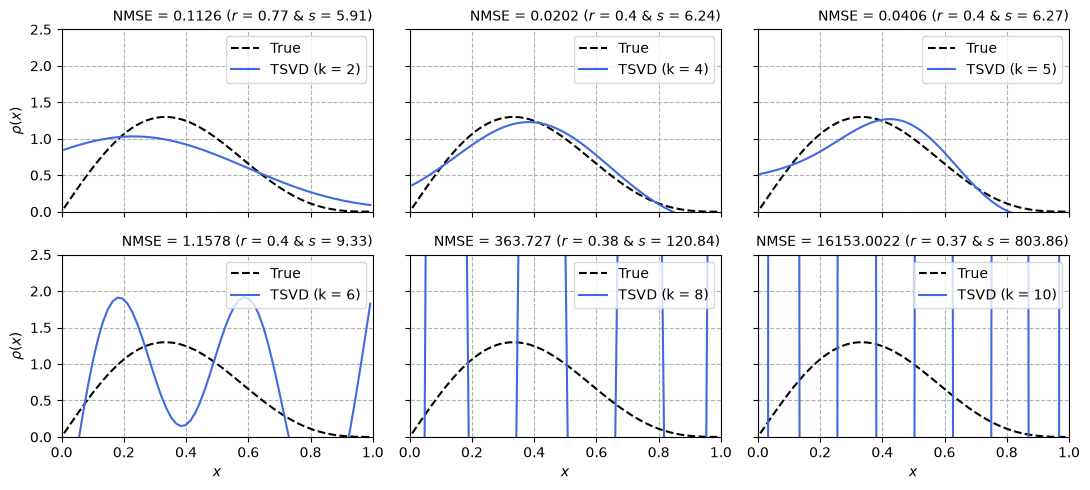

In [16]:
fig, axs = plt.subplots(2, 3, figsize = (11,5), sharex=True, sharey=True)
j = 0
for row in np.arange(2):
    for col in np.arange(3):
        axs[row,col].plot(problem.x, problem.x_true, '--k', label = 'True')
        axs[row,col].plot(problem.x, x_est[j], color = 'royalblue', label = r'TSVD (k = {})'.format(ks[j]))
        axs[row,col].set_title(r'NMSE = {} ($r$ = {} & $s$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[1,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

### What we notice is
- If $k$ is too small, we suppress useful singular value components of the source term. The consequence is a solution that tends to be over-smoothed. The solutions will have high residual (approaching its maximum as $k \rightarrow 0$). The problem is over-regularized, leading to **underfitting**.
- also note that $s$ tends to be small as $k$ increases for $k<4$. This corresponds to **underfitting** or an over-regularized solution. In this case, some useful components (associated with the exact solution value) are suppressed. The consequence is a solution that tends to be over-smoothed.
- As $k$ increases, the NMSE decreases in principle (up to $k=4$). Beyond a certain point, including more SVD components becomes detrimental, and the NMSE increases considerably. Look at Picard’s plot and pay attention to the details. The increase in NMSE is due to the inclusion of more noisy SVD components.
- As $k$ increases, the norm of the residual ($r$) decreases. Surprisingly, this holds even for $k>4$. This is **overfitting** or an under-regularized solution;
- Note that the norm of the solution, $s$, increases as $k$ increases. When $k>4$, it tends to become excessively large. **Overfitting** means that the TSVD has included more information about the noise than about the source term in the solution;


## 4.3. Tikhonov regularization

The advantage of the **TSVD** method is that it is intuitive and makes it easy to compute the solutions, $\hat{\mathbf{x}}_k$, for different values of $k$. The disadvantage is that it is a brute-force method in which the filtering parameters $\varphi_i$ are abruptly truncated.

Probably, the most successful regularization method of all time is **Tikhonov regularization**. The Tikhonov method explicitly incorporates the regularity requirement into the problem statement, defined as the following solution to the optimization problem:

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \text{min}(\left\|\textbf{Ax-b}\right\|^{2}_{2} + \lambda^2\left\|\textbf{x}\right\|^{2}_{2}).
\tag{21}
\end{equation}
where $\lambda>0$ is the regularization parameter, which controls the weights of the two components in the minimization, namely

- **residual norm** $\rho = \left\|\textbf{Ax-b}\right\|^{2}_{2}$, which measures the quality of the fit. Obviously, if this term is too large, then $\hat{\textbf{x}}_{\lambda}$ cannot be considered a good solution, since it does not “solve the problem.” On the other hand, intuitively, we should not make the residual smaller than the average magnitude of the errors in $\textbf{b}$; as in data-fitting problems, we do not want to **overfit** our model to the noise present in the data.

- **norm of the solution** $\xi = \left\|\textbf{x}\right\|^{2}_{2}$, which measures the smoothness of the solution. The inclusion of this term is based on our knowledge that the naive solution is dominated by high-frequency components with large amplitudes. The hope, therefore, is that if we control the norm of $\textbf{x}$, we can suppress most of the noisy components.

### The regularization path in the Tikhonov solution

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
The balance between the two terms is controlled by the factor $\lambda^2$ (or $\lambda$ in some textbooks). The larger $\lambda$ is, the greater the weight given to minimizing the solution's norm, $\left\|\textbf{x}\right\|^{2}_{2}$, and, therefore, the more regularized the solution will be. We note that $\left\|\textbf{x}\right\|^{2}_{2}\rightarrow 0$ as $\lambda \rightarrow \infty$. On the other hand, the smaller $\lambda$ is, the greater the weight given to fitting the noisy data, resulting in less regularized solutions (we obtain the least-squares solution when $\lambda = 0$).
</div>

### Analytical Solution

It can be shown that the Tikhonov solution has an analytical solution to the following least-squares problem:

\begin{gather}
\hat{\textbf{x}}_{\lambda} = \text{min}\left(\left\|
  \begin{bmatrix}
   \textbf{A} \\ \lambda \textbf{I}
   \end{bmatrix}
   -
   \begin{bmatrix}
   \textbf{b} \\ \textbf{0}
   \end{bmatrix}
   \right\|_{2}\right)
\end{gather}
with the solution given by:

\begin{equation}
\hat{\textbf{x}}_{\lambda} = (\textbf{A}^H\textbf{A}+\lambda^2\textbf{I})^{-1}\textbf{A}^H \textbf{b}
\tag{22}
\end{equation}

**NOTE**: The SVD preserves the original dimensions of $\textbf{A}$, while $\textbf{A}^H\textbf{A}$ [$(L \times M) \times (M \times L)$] may have much larger dimensions in underdetermined systems and, therefore, have an even worse condition number than that of the original problem.

We can use the expansion $\textbf{A} = \textbf{U} \Sigma \textbf{V}^H$ and its pseudoinverse, and recall that $\textbf{V}^H\textbf{V} = \textbf{I}$. Thus, we obtain

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \textbf{V}(\Sigma^2+\lambda^2\textbf{I})^{-1} \ \Sigma \textbf{U}^H \textbf{b}
\tag{23}
\end{equation}

which, compared to Eq. (19) allows us to infer that the **filter factors** are

\begin{equation}
    \varphi_{i}^{[\lambda]} = \frac{\sigma_{i}^{2}}{\sigma_{i}^{2}+\lambda^2} \approx
    \begin{cases}
      1 \ \ \ \ \ \ \ \ \ \ \ \ \ \ \lambda \ll \sigma_i \\
      \sigma_{i}^{2}/\lambda^2 \ \ \ \ \ \ \ \lambda \gg \sigma_i
    \end{cases}
\tag{24}
\end{equation}

Let’s see what happens when we use different values for $\lambda$.

In [17]:
lambdas = [2.5, 0.7, 0.2, 0.05, 0.01, 0.001]
x_est = []
nmse = []
sol_norm = []
res_norm = []
for lam in lambdas:
    xh = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam)
    x_est.append(xh)
    nmse.append(pyregtools.utils.nmse_fun(xh, problem.x_true))
    sol_norm.append(np.linalg.norm(xh))
    res_norm.append(np.linalg.norm(problem.A @ xh - problem.b_noisy))

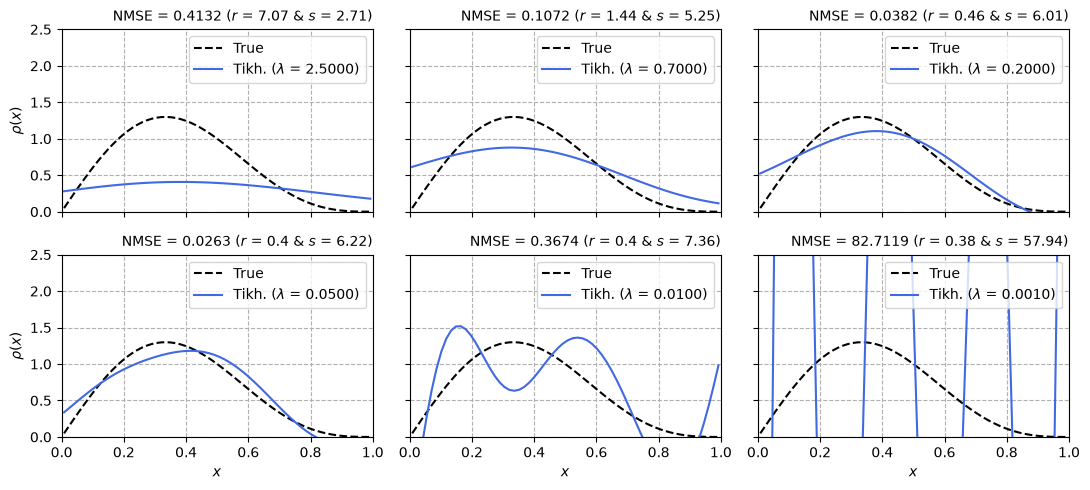

In [18]:
fig, axs = plt.subplots(2, 3, figsize = (11,5), sharex=True, sharey=True)
j = 0
for row in np.arange(2):
    for col in np.arange(3):
        axs[row,col].plot(problem.x, problem.x_true, '--k', label = 'True')
        axs[row,col].plot(problem.x, x_est[j], color = 'royalblue', label = r'Tikh. ($\lambda$ = {0:.4f})'.format(lambdas[j]))
        axs[row,col].set_title(r'NMSE = {} ($r$ = {} & $s$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[1,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

### What we notice is
- If $\lambda$ is too large, we suppress useful singular value components of the source term. The consequence is a solution that tends to be over-smoothed. The solutions will have high residual (approaching the maximum as $\lambda \rightarrow \infty$). The problem is over-regularized, leading to **underfitting**.
- As $\lambda$ decreases, the NMSE decreases in principle. For $\lambda < 0.05$, the NMSE increases considerably.
- As $\lambda$ decreases, the residual norm ($r$) decreases. Surprisingly, this holds even for $\lambda < 0.05$. This is **overfitting** or an under-regularized solution;
- Note that the norm of the solution, $s$, increases in principle ($2.5 < \lambda < 0.05$). When $\lambda < 0.05$, it tends to increase until it becomes excessively large for very small values (cases in which the Tikhonov solution will resemble the least-squares solution more and more, which tends to exhibit **overfitting**);

# 5. Choosing the optimal regularization parameter

Now, the immediate question is: **can we choose an optimal value for $\lambda$?**

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
The good news is that the answer is yes, and there are more than one method that does not require computing multiple solutions or matrix factorizations. Furthermore, this is one of the tasks for which PyRegTools was built.
</div>

<br>

To follow the implementation in the `regchoice` module of `PyRegTools`, it is useful to revisit Eq. (19) and write out the residual and solution norms. We will annotate some terms that are important to follow the computational implementation. For the Tikhonov solution, the square of the $\ell_2$ solution norm is

\begin{equation}
\eta = \left\|\textbf{x}_{\lambda}\right\|_{2}^{2}=\sum_{i=1}^{L}\varphi_{i}^2 \left|\frac{\boldsymbol{\beta}_i}{\sigma_{i}}\right|^{2}, 
\tag{25}
\end{equation}

where $\boldsymbol{\beta}_i = \textbf{u}_{i}^{H} \textbf{b}$ is the projection of the measured data on the $i$-th column vector of the left singular vector matrix, and $\varphi_{i} = \frac{\sigma_i^2}{\sigma_i^2+\lambda^2}$ is the $i$-th filter factor. Then, the square of the residual $\ell_2$ norm is


\begin{equation}
\rho = \left\|\textbf{A x}_{\lambda}-\textbf{b}\right\|_{2}^{2}=\sum_{i=1}^{L}\left(1-\varphi_{i}\right)^2 |\boldsymbol{\beta}|^{2}+ \epsilon^2_\bot,
\tag{26}
\end{equation}
where $1-\varphi_{i} = \frac{\lambda^2}{\sigma_i^2+\lambda^2}$ is the complement of $i$-th filter factor, and $\epsilon_\bot^2 = \|\mathbf{b}\|_2^2-\|\boldsymbol{\beta}\|_2^2$ is the norm of the components of $\mathbf{b}$ outside the column space of $\mathbf{A}$.

This terminology is used across the regularization parameter selection methods in `PyRegTools`. Let's investigate a few of such methods in some detail.

## 5.1. Discrepancy Principle (DP)

Let’s start with the **simplest** and most intuitive approach. The **discrepancy** principle tells us that we should choose the parameter $\lambda$ (Tikhonov) such that the residual norm ($\rho = \left\|\textbf{A}\textbf{x}_{\lambda}-\textbf{b}\right\|_{2}^{2}$) is equal to the assumed squared noise norm ($\left\|\textbf{n}\right\|_{2}^{2}$), multiplied by a real factor $\upsilon_{\text{DP}}$. The product $\upsilon_{\text{DP}}\left\|\textbf{n}\right\|_{2}^{2}$ is then called the **discrepancy**.

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
\begin{equation}
\text{Choose} \ \ \ \lambda  \ \ \ \text{such that} \ \ \ \rho - \upsilon_{\text{DP}}\left\|\textbf{n}\right\|_{2}^{2} = 0
\tag{27}
\end{equation}
</div>

<br>

In both cases, there is a unique solution, since $\rho$ varies monotonically with $\lambda$.

The main computational advantage of DP is its simplicity. Only the residual norm is involved, and all we need is a root-finding algorithm.

The main drawback of DP is that we often do not know the noise norm, $\left\|\textbf{n}\right\|_2$, exactly. Unfortunately, the quality of the resulting regularization parameter is very sensitive to the accuracy of the estimate of $\upsilon_{\text{DP}}\left\|\textbf{n}\right\|_{2}$. In particular, an estimate that is too small can lead to severe **overfitting** (the resulting $\lambda$ computed by DP is too small). The opposite also occurs when either $\upsilon_{\text{DP}}$ or $\left\|\textbf{n}\right\|_2$ is overestimated.

In `PyRegTools`, the module `regchoice` provides the means to compute the optimal $\lambda$ via the discrepancy principle using the method `discrep`. 
Let’s see how it handles the gravity survey problem.

In [19]:
def plot_sol(x_sol, lam, nmse, res_norm, sol_norm):
    """ plot the solution (helper function to compare with x_true)
    """
    plt.figure(figsize = (5,3))
    plt.plot(problem.x, problem.x_true, '--k', label = 'True')
    plt.plot(problem.x, x_sol, color = 'royalblue', linewidth = 1.5, label = r'Tikhonov ($\lambda$ = {0:.4f})'.format(lam))
    plt.title(r'NMSE = {:.3f} ($r$ = {:.2f} & $s$ = {:.2f})'.format(nmse, res_norm, sol_norm), loc = 'right', fontsize=10)
    plt.grid(linestyle = '--')
    plt.legend()
    plt.xlim((problem.lb, problem.ub))
    plt.ylim((-0.05, 2.5)) 
    plt.xlabel(r'$x$')
    plt.ylabel(r'$\rho(x)$')
    plt.tight_layout()

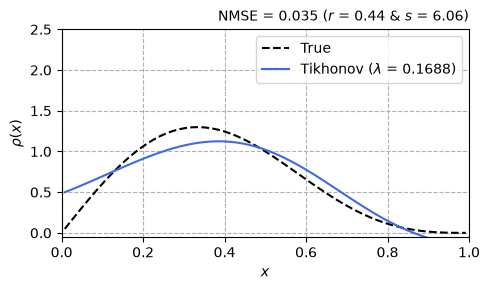

In [20]:
noise_norm = 10**(-snr / 20) * np.linalg.norm(problem.b_true)
lam_dp = regchoice.discrep(u, s, problem.b_noisy, noise_norm) # evoke reg choice method
x_dp = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_dp) # evoke tikhonov solver passing the optimal reg parameter
nmse_dp = pyregtools.utils.nmse_fun(x_dp, problem.x_true)  
res_norm = np.linalg.norm(problem.A @ x_dp - problem.b_noisy)
sol_norm = np.linalg.norm(x_dp)
plot_sol(x_dp, lam_dp, nmse_dp, res_norm, sol_norm)

## 5.2. The L-curve criterion

One approach to choosing $\lambda$ is to use the heuristic behavior of the log-log curve of the residual vs. the solution norm. 

Let's investigate the behavior as we plot several solution candidates varying $\lambda$. You will notice that:

- the curve has an "L" shape, which is typical in many practical inverse problems;
- for very small $\lambda$, the solution norm is very large, and the residual norm is at its minimum, indicating severe overfitting;
- for large $\lambda$, the solution norm can get unrealistically small, and the residual norm is large, indicating severe underfitting;
- the optimal value lies at the corner of the L-shaped curve;

In [21]:
# Several lambda values
lambdas = np.logspace(-5, 1, num=100) # logspace from 0.00001 to 10
# Solution and residual norms init
sol_norms = np.zeros(len(lambdas))
residuals = np.zeros(len(lambdas))
# loop
for jl, lam in enumerate(lambdas):
    xlam = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam)
    sol_norms[jl] = np.linalg.norm(xlam)
    residuals[jl] = np.linalg.norm(problem.A @ xlam - problem.b_noisy)
chosen_indexes = [33, 41, 55, 75, 85, 95]

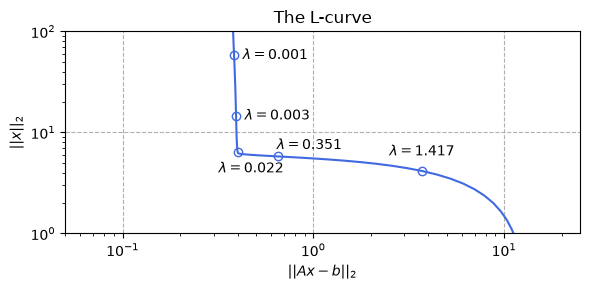

In [22]:
plt.figure(figsize = (6,3))
plt.loglog(residuals, sol_norms, color = 'Royalblue')
plt.loglog(residuals[chosen_indexes], sol_norms[chosen_indexes],  'o', color = 'Royalblue', markerfacecolor='none')
for num in chosen_indexes[:2]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(30, -3), ha='center') 
for num in chosen_indexes[2:3]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(10, -15), ha='center')
for num in chosen_indexes[3:4]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(23, 5), ha='center')
for num in chosen_indexes[4:6]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(0, 11), ha='center') 
plt.grid(linestyle = '--')
plt.ylim((1, 100))
plt.xlim((0.05, 25))
plt.xlabel(r'$||A x - b||_2$')
plt.ylabel(r'$||x||_2$')
plt.title("The L-curve")
plt.tight_layout()

The L-curve represents the relationship between the residual norm and the solution norm as the regularization parameter $\lambda$ varies. Using the SVD representation of the Tikhonov solution and Eqs. (25) and (26), these quantities can be expressed as

\begin{equation}
\eta(\lambda) = \|\mathbf{x}_\lambda\|_2
=
\left(\sum_{i=1}^{L}\varphi_i^2|\xi_i|^2\right)^{1/2},
\end{equation}

\begin{equation}
\rho(\lambda) = \|\mathbf{A}\mathbf{x}_\lambda-\mathbf{b}\|_2
=
\left(\sum_{i=1}^{L}(1-\varphi_i)^2|\beta_i|^2+\epsilon_\perp^2\right)^{1/2},
\end{equation}

where $\xi_i=\beta_i/\sigma_i$. The L-curve is parametrized by

\begin{equation}
\left(\log\rho(\lambda),\log\eta(\lambda)\right).
\end{equation}

We aim to find the corner of the L-curve, which can be done by finding the $\lambda$ that maximizes the negative of its curvature, given by

\begin{equation}
C(\lambda) = \frac{\widehat{\rho}'\widehat{\eta}''- \widehat{\eta}'\widehat{\rho}''
}{\left[(\widehat{\rho}')^2+(\widehat{\eta}')^2\right]^{3/2}},
\tag{28}
\end{equation}

where $\widehat{\rho}=\log\rho$, $\widehat{\eta}=\log\eta$, and primes denote derivatives with respect to $\lambda$. For standard-form Tikhonov regularization, the filter factors and their derivatives are

\begin{equation}
\varphi_i=\frac{\sigma_i^2}{\sigma_i^2+\lambda^2},
\qquad
\varphi_i'=-\frac{2\varphi_i(1-\varphi_i)}{\lambda},
\qquad
\varphi_i''=-\frac{\varphi_i'(3-4\varphi_i)}{\lambda}.
\end{equation}

To simplify the calculation, we define four intermediate quantities:

\begin{equation}
\begin{aligned}
\phi &= \sum_{i=1}^{L}\varphi_i\varphi_i'|\xi_i|^2,\\
\psi &= \sum_{i=1}^{L}(1-\varphi_i)\varphi_i'|\beta_i|^2,\\
\phi' &= \sum_{i=1}^{L}\left[(\varphi_i')^2+\varphi_i\varphi_i''\right]|\xi_i|^2,\\
\psi' &= \sum_{i=1}^{L}\left[-(\varphi_i')^2+(1-\varphi_i)\varphi_i''\right]|\beta_i|^2.
\end{aligned}
\end{equation}

These quantities are related to the derivatives of the norms through

\begin{equation}
\eta'=\frac{\phi}{\eta},
\qquad
\rho'=-\frac{\psi}{\rho},
\end{equation}

and

\begin{equation}
\eta''=\frac{\phi'}{\eta}-\frac{\phi^2}{\eta^3},
\qquad
\rho''=-\frac{\psi'}{\rho}-\frac{\psi^2}{\rho^3}.
\end{equation}

Thus, the L-curve curvature can be evaluated analytically from the SVD coefficients and filter factors, without numerical differentiation, using the method `l_curve` from `regchoice`. Let’s see how it handles the gravity survey problem.

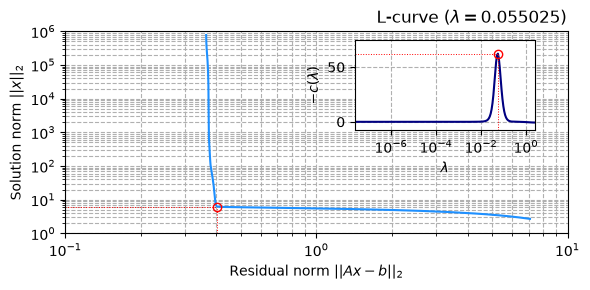

In [23]:
lam_l = regchoice.l_curve(u, s, problem.b_noisy, r_min = 1e-8, plotit = True) # evoke reg choice method

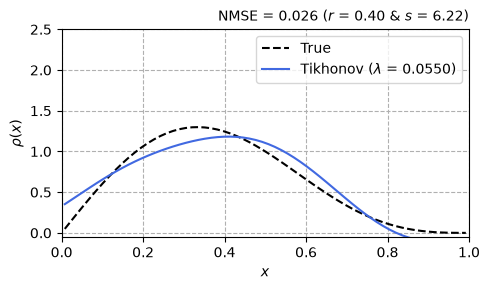

In [24]:
x_l = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_l) # evoke tikhonov solver passing the optimal reg parameter
nmse_l = pyregtools.utils.nmse_fun(x_l, problem.x_true)  
res_norm = np.linalg.norm(problem.A @ x_l - problem.b_noisy)
sol_norm = np.linalg.norm(x_l)
plot_sol(x_l, lam_l, nmse_l, res_norm, sol_norm)

Technically speaking, what the `l_curve` method does is:

- Initialize a vector of possible $\lambda$'s with a geometrical progression from $\sigma_1$ to $\max(\sigma_L, r \sigma_1)$, $r<1$ represents a ratio. The use of $\max(\sigma_L, r \sigma_1)$ avoids searching for very small values of $\lambda$ (that could lead to a least-square solution);
- Compute a set of discrete curvature values: $[-C(\lambda_1), -C(\lambda_2), \ldots, -C(\lambda_K)]^T$;
- Find the $\lambda$ which corresponds to the maximum of the negative of the curvature vector;
- Compute a reasonable interval for the true $\lambda$ using the adjacent values to the $\lambda$ of the previous step;
- Use an optimization algorithm to refine the value of the ideal $\lambda$;

The steps are common to 2 other methods implemented in `PyRegTools`: Generalized Cross-Validation (GCV) and the Normalized Cumulative Periodogram (NCP).

## 5.3. Generalized Cross-Validation (GCV)

The main idea behind **Generalized Cross-Validation (GCV)** is to select the regularization parameter $\lambda$ that best predicts the noise-free data $\mathbf{b}_{\mathrm{exact}}$, which is unknown in practice.

In ordinary **cross-validation**, some measurements are excluded when computing the solution and are subsequently used to evaluate its predictive accuracy. For example, we could omit the $i$-th measurement, compute a regularized solution using the remaining data, and compare the predicted value with the omitted measurement $b_i$. Repeating this procedure for all $M$ measurements would be computationally expensive. GCV provides an efficient alternative by using the average influence of the measurements on the fitted solution.

For Tikhonov regularization, the predicted data can be written as

\begin{equation}
\widehat{\mathbf{b}} = \mathbf{H}_{\lambda}\mathbf{b},
\end{equation}

where $\mathbf{H}_{\lambda}$ is the *hat matrix*, defined as

\begin{equation}
\mathbf{H}_{\lambda}
=
\mathbf{A}
\left(\mathbf{A}^H\mathbf{A}+\lambda^2\mathbf{I}\right)^{-1}
\mathbf{A}^H.
\end{equation}

The GCV function is proportional to the squared residual norm divided by a correction factor involving the trace of the hat matrix:

\begin{equation}
G(\lambda)
=
\frac{
\|\mathbf{A}\mathbf{x}_{\lambda}-\mathbf{b}\|_2^2
}{
\left[M-\operatorname{tr}(\mathbf{H}_{\lambda})\right]^2
}.
\end{equation}

Here, $M$ is the number of measurements, and $\operatorname{tr}(\mathbf{H}_{\lambda})$ represents the effective number of degrees of freedom used by the regularized solution.

Using the SVD, we obtain

\begin{equation}
\operatorname{tr}(\mathbf{H}_{\lambda})
=
\sum_{i=1}^{L}\varphi_i,
\end{equation}

where $\varphi_i^{[\lambda]}$ are the Tikhonov filter factors.

Therefore, the GCV function can be evaluated directly from the SVD coefficients:

\begin{equation}
G(\lambda) = \frac{\displaystyle \sum_{i=1}^{L} \left(1-\varphi_i^{[\lambda]}\right)^2|\beta_i|^2 + \epsilon_\perp^2}{
\displaystyle \left(M-\sum_{i=1}^{L}\varphi_i\right)^2} = \frac{\displaystyle \sum_{i=1}^{L} \left(1-\varphi_i^{[\lambda]}\right)^2|\beta_i|^2 + \epsilon_\perp^2}{
\displaystyle \left(M-L+\sum_{i=1}^{L}(1-\varphi_i)\right)^2}
\tag{29}
\end{equation}

We aim to find the $\lambda$ that minimizes the GCV function in Eq. (29).

Unlike the L-curve criterion, which seeks a compromise between the residual and solution norms, **GCV estimates predictive performance from the measured data**. It does not require knowledge of the exact solution or the noise level.

In `PyRegTools`, GCV can be evaluated efficiently using the SVD, without computing a separate regularized solution for every candidate value of $\lambda$. The method `gcv_lambda` from `regchoice` is used in this case. Let’s see how it handles the gravity survey problem.

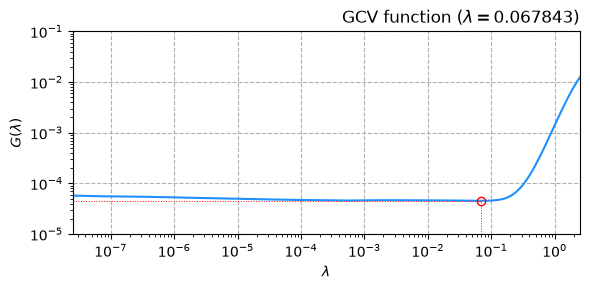

In [25]:
lam_gcv = regchoice.gcv_lambda(u, s, problem.b_noisy, r_min = 1e-8, plotit = True) # evoke reg choice method

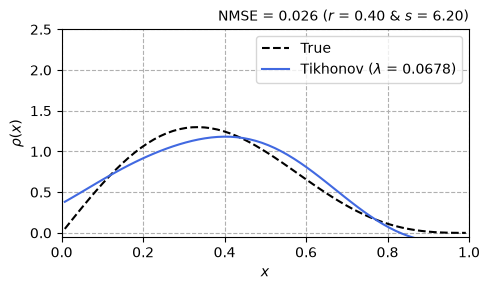

In [26]:
x_gcv = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_gcv) # evoke tikhonov solver passing the optimal reg parameter
nmse_gcv = pyregtools.utils.nmse_fun(x_gcv, problem.x_true)  
res_norm = np.linalg.norm(problem.A @ x_gcv - problem.b_noisy)
sol_norm = np.linalg.norm(x_gcv)
plot_sol(x_gcv, lam_gcv, nmse_gcv, res_norm, sol_norm)

## 5.4. Normalized Cumulative Periodogram (NCP)

Unlike the L-curve and GCV methods, which rely on the residual and solution norms, the **Normalized Cumulative Periodogram (NCP)** analyzes the frequency content of the residual vector. For Tikhonov regularization, the residual is

\begin{equation}
\mathbf{r}_{\lambda} = \mathbf{A}\mathbf{x}_{\lambda}-\mathbf{b},
\tag{30}
\end{equation}

where $\mathbf{b}=\mathbf{b}_{\mathrm{exact}}+\mathbf{n}$ contains the noise-contaminated measurements.

The main idea is simple: **a suitable regularized solution should explain the meaningful information in the measurements, leaving a residual that resembles measurement noise.**

If the measurement noise is white, its expected power spectrum is approximately flat. We can therefore examine whether the residual exhibits this spectral behavior.

### Computing the NCP

First, compute the Discrete Fourier Transform (DFT) of the residual, typically using the FFT:

\begin{equation}
\widehat{\mathbf{r}}_{\lambda}
=
\operatorname{DFT}\{\mathbf{r}_{\lambda}\}.
\tag{31}
\end{equation}

The periodogram is obtained from the squared magnitudes of its Fourier coefficients:

\begin{equation}
p_i=\left|\widehat{r}_{\lambda}^{(i)}\right|^2.
\tag{32}
\end{equation}

For real-valued residuals, we use the nonnegative-frequency components of the spectrum. The DC component is excluded, and the remaining $Q$ spectral components are used to construct the normalized cumulative periodogram:

\begin{equation}
c_i(\mathbf{r}_{\lambda})
=
\frac{\displaystyle\sum_{j=1}^{i}p_j}
{\displaystyle\sum_{j=1}^{Q}p_j},
\qquad i=1,\ldots,Q.
\tag{33}
\end{equation}

By construction, the last NCP value is equal to one.

For white noise, the expected NCP follows a straight line:

\begin{equation}
\mathbf{c}_{\mathrm{white}}
=
\left(\frac{1}{Q},\frac{2}{Q},\ldots,1\right)^T.
\tag{34}
\end{equation}

Therefore, when the NCP of the residual approaches this reference line, the residual becomes spectrally similar to white noise. We quantify the difference between the residual NCP and the white-noise reference using:

\begin{equation}
d(\lambda)
=
\left\|
\mathbf{c}(\mathbf{r}_{\lambda})
-
\mathbf{c}_{\mathrm{white}}
\right\|_2.
\tag{35}
\end{equation}

The regularization parameter is selected by finding the $\lambda$ that minimizes the distance in Eq. (35).

The NCP method does not require knowledge of the exact solution or the noise level. However, it assumes that the measurement noise is approximately white. The method `ncp` from `regchoice` is used in this case. Let’s see how it handles the gravity survey problem.

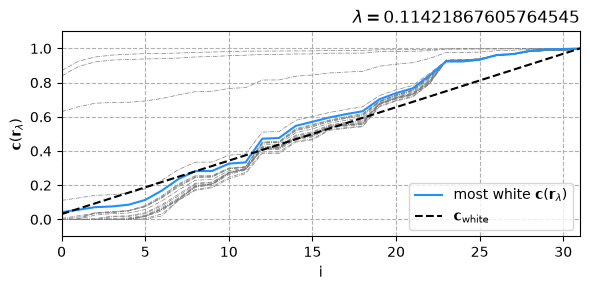

In [27]:
lam_ncp = regchoice.ncp(u, s, problem.b_noisy, r_min = 1e-8, plotit = True) # evoke reg choice method

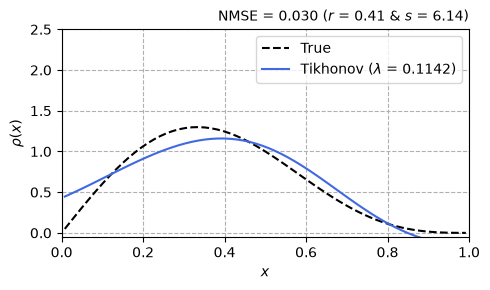

In [28]:
x_ncp = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_ncp) # evoke tikhonov solver passing the optimal reg parameter
nmse_ncp = pyregtools.utils.nmse_fun(x_ncp, problem.x_true)  
res_norm = np.linalg.norm(problem.A @ x_ncp - problem.b_noisy)
sol_norm = np.linalg.norm(x_ncp)
plot_sol(x_ncp, lam_ncp, nmse_ncp, res_norm, sol_norm)

# 6. Reconstruction

Once we have obtained a good approximation of the source responsible for the measured phenomenon, we can use it to predict the physical field at locations where no measurements were taken. In other words, we wish to **reconstruct** the quantity of interest at unobserved locations.

For example, in the gravity survey problem, we measure the gravitational acceleration $g(x')$ at a distance $d$ [m] from the source and estimate the density distribution $\rho(x)$. We may then wish to reconstruct the gravitational acceleration at distances smaller or larger than the original measurement distance.

Note that:

- $d=0$ m represents the hypothetical location of the density sources. In general, reconstruction should be restricted to a **source-free region**, meaning that we should avoid $d\leq 0$.
- We can reconstruct $g(x')$ at other values of $d$, either closer to or farther from the source than the original measurement plane.

Importantly, reconstruction is a **forward problem**. Since we have already estimated the source distribution $\hat{\mathbf{x}}$ by solving the regularized inverse problem, we simply compute

\begin{equation}
\mathbf{b}_{\mathrm{r}}
=
\mathbf{A}_{\mathrm{r}}\hat{\mathbf{x}},
\tag{36}
\end{equation}

where $\mathbf{A}_{\mathrm{r}}$ is the forward operator evaluated at the desired reconstruction locations.

Let's do something simple: we can use the original `problem` object, change the distance $d$, and compute a noiseless measurement using `noiseless_meas`. This will give us the new `b_true` (at the desired reconstruction location) and the reconstruction matrix. We can then use Eq. (36) with the Tikhonov solution that used the $\lambda$ obtained from the L-curve criterion.

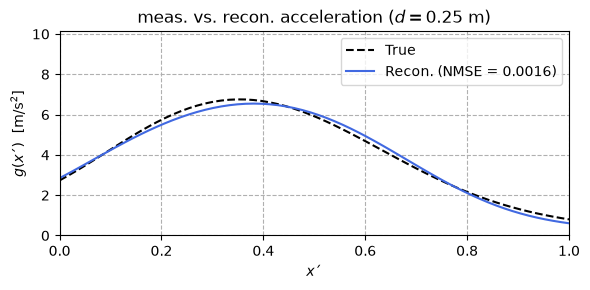

In [29]:
### True value
problem.d = 0.25
problem.noiseless_meas()
### reconstruction
b_recon = problem.A @ x_l
nmse_recon = pyregtools.utils.nmse_fun(b_recon, problem.b_true)  

plt.figure(figsize = (6,3))
plt.plot(problem.coord, problem.b_true, '--k', label = 'True')
plt.plot(problem.coord, b_recon, color = 'royalblue', label = 'Recon. (NMSE = {:.4f})'.format(nmse_recon))
plt.legend()
plt.grid(linestyle = '--')
plt.xlabel(r'$x´$')
plt.ylabel(r'$g(x´)$  [m/s$^2$]')
plt.xlim((0, 1))
plt.ylim((0, 1.5*np.amax(problem.b_true)))
plt.title(r'meas. vs. recon. acceleration ($d = {}$ m)'.format(problem.d))
plt.tight_layout()

#### Reconstruction error as a function of the distance

We can also explore how the NMSE changes as the distance changes. You will notice that as we try to reconstruct nearer and nearer to the source term, the reconstruction error tends to increase. This is the effect of amplifying the higher-frequency noisy terms that have decayed to the noise level at the $d = 0.5$ [m] measurement location.

In [30]:
d_vec = np.linspace(1e-4, 1, 100)
nmse_recon = np.zeros(len(d_vec))
for j, d in enumerate(d_vec):
    problem.d = d
    problem.noiseless_meas()
    ### reconstruction
    b_recon = problem.A @ x_l
    nmse_recon[j] = pyregtools.utils.nmse_fun(b_recon, problem.b_true)  

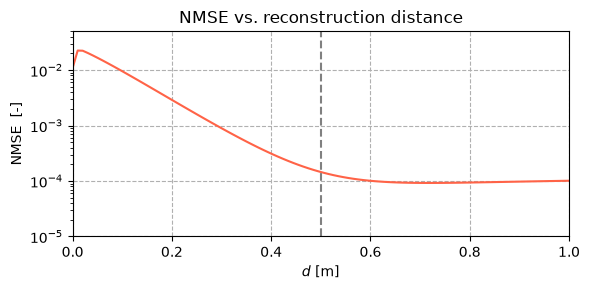

In [31]:
plt.figure(figsize = (6,3))
plt.semilogy(d_vec, nmse_recon, color = 'tomato')
plt.axvline(0.5, linestyle = '--', color = 'grey')
plt.grid(linestyle = '--')
plt.xlabel(r'$d$ [m]')
plt.ylabel(r'NMSE  [-]')
plt.xlim((0, d_vec[-1]))
plt.ylim((1e-5, 0.05))
plt.title(r'NMSE vs. reconstruction distance')
plt.tight_layout()

# 7. Concluding remarks

In this notebook, we explored a gravity survey problem to illustrate some fundamental aspects of discrete inverse problems.

We observed how the forward operator smooths the source distribution, making the recovery of high-spatial-frequency information particularly sensitive to noise. The SVD helped us understand this instability, while regularization provided a way to obtain more reasonable solutions.

We also investigated several criteria for selecting the regularization parameter: the discrepancy principle, L-curve, GCV, and NCP. Each method approaches the problem differently, and their performance depends on the properties of the measurements and the inverse problem.

Finally, we used a regularized source estimate to reconstruct the gravitational field at locations where no measurements were available, illustrating both the usefulness and the limitations of inverse solutions.